In [ ]:
# import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import plotly
import plotly.express as px
import plotly.figure_factory as ff

  State Name county Name  State Code  County Code        Date  AQI Category  \
0    Alabama     Baldwin           1            3  2023-01-10   47     Good   
1    Alabama     Baldwin           1            3  2023-01-11   38     Good   
2    Alabama     Baldwin           1            3  2023-01-12   30     Good   
3    Alabama     Baldwin           1            3  2023-01-13   24     Good   
4    Alabama     Baldwin           1            3  2023-01-14   27     Good   

  Defining Parameter Defining Site  Number of Sites Reporting  
0              PM2.5   01-003-0010                          1  
1              PM2.5   01-003-0010                          1  
2              PM2.5   01-003-0010                          1  
3              PM2.5   01-003-0010                          1  
4              PM2.5   01-003-0010                          1  
Index(['State Name', 'county Name', 'State Code', 'County Code', 'Date', 'AQI',
       'Category', 'Defining Parameter', 'Defining Site',
   

<ipython-input-6-a5a8f9c5d46b>:20: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_wildfires = df_aqi[(df_aqi['Date'] >= start_date) & (df_aqi['Date'] <= end_date)][(df_aqi['State Name'] == state)]


             Date  AQI Defining Parameter
183992 2023-05-13   51              PM2.5
184000 2023-05-21   57              PM2.5
184001 2023-05-22   55              PM2.5
184002 2023-05-23   58              PM2.5
184006 2023-05-27   52              PM2.5


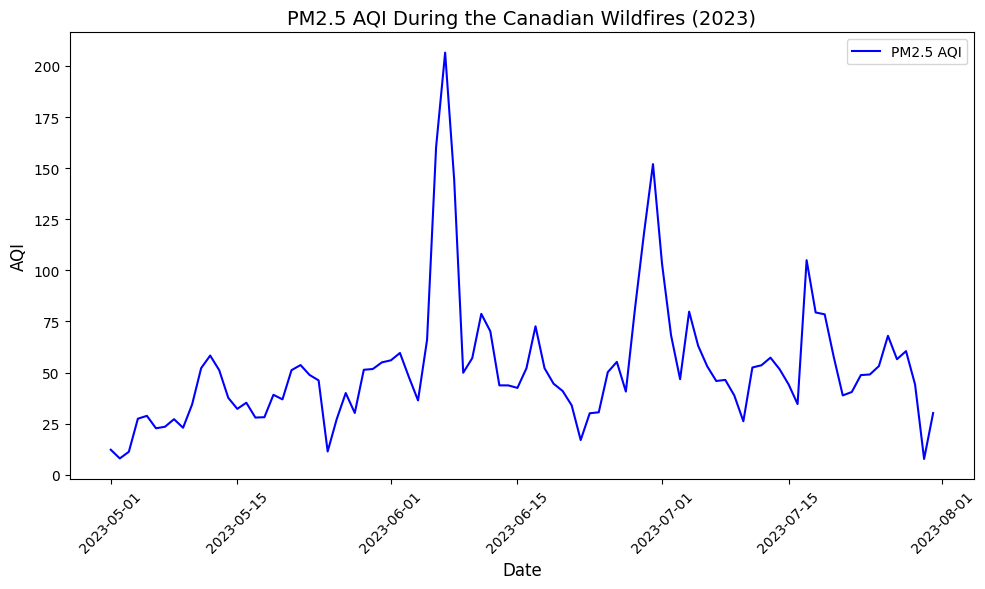

Average AQI based on PM2.5 during the wildfires: 61.07


In [ ]:
# load dataset
df_aqi = pd.read_csv('daily_aqi_by_county_2023.csv')

# inspect dataset to understand structure
print(df_aqi.head())

# check for column names and data types
print(df_aqi.columns)
print(df_aqi.info())

# convert date column to datetime format
df_aqi['Date'] = pd.to_datetime(df_aqi['Date'])

# filter data for the time period and area of effects of the Canadian wildfires
# major wildfires in Canada occurred from May to July 2023
start_date = '2023-05-01'
end_date = '2023-07-31'
state = 'New York'

df_wildfires = df_aqi[(df_aqi['Date'] >= start_date) & (df_aqi['Date'] <= end_date)][(df_aqi['State Name'] == state)]

# filter for specific pollutants
df_pm25 = df_wildfires[df_wildfires['Defining Parameter'] == 'PM2.5']

# check the filtered data
print(df_pm25[['Date', 'AQI', 'Defining Parameter']].head())

#grouping data points by date
df_pm25agg=df_pm25.groupby('Date').agg(
    {'AQI': 'mean'}
).reset_index()

# analyze AQI trend for PM2.5
plt.figure(figsize=(10, 6))
plt.plot(df_pm25agg['Date'], df_pm25agg['AQI'], label='PM2.5 AQI', color='blue')
plt.title('PM2.5 AQI During the Canadian Wildfires (2023)', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('AQI', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.legend()
plt.show()

# calculate the average AQI for PM2.5 during the wildfire period
avg_pm25_aqi = df_pm25['AQI'].mean()
print(f"Average AQI based on PM2.5 during the wildfires: {avg_pm25_aqi:.2f}")

       Date Source    Site ID  POC  Daily Max 1-hour NO2 Concentration Units  \
0  1/1/2023    AQS  340030010    1                                30.7   ppb   
1  1/2/2023    AQS  340030010    1                                33.7   ppb   
2  1/3/2023    AQS  340030010    1                                68.4   ppb   
3  1/4/2023    AQS  340030010    1                                33.3   ppb   
4  1/5/2023    AQS  340030010    1                                21.7   ppb   

   Daily AQI Value     Local Site Name  Daily Obs Count  Percent Complete  \
0               28  Fort Lee Near Road               21                88   
1               31  Fort Lee Near Road               24               100   
2               66  Fort Lee Near Road               24               100   
3               31  Fort Lee Near Road               24               100   
4               20  Fort Lee Near Road               24               100   

   ...  AQS Parameter Description Method Code  CBSA Code

<ipython-input-4-8ebe46902d55>:18: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_no2_filtered = df_no2[(df_no2['Date'] >= start_date) & (df_no2['Date'] <= end_date)][(df_no2['State'] == state)]


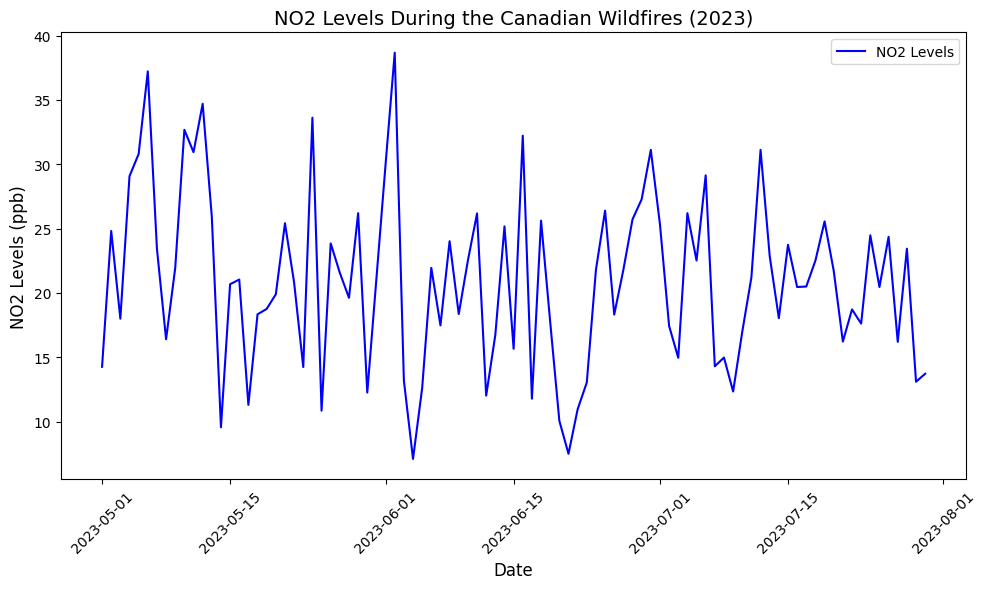

In [ ]:
#Load NO2 dataset
df_no2 = pd.read_csv('no2_NYCarea.csv')

# inspect dataset to understand structure
print(df_no2.head())

# check for column names and data types
print(df_no2.columns)
print(df_no2.info())

# convert date column to datetime format
df_no2['Date'] = pd.to_datetime(df_no2['Date'])

#Rename column for ease of use
df_no2=df_no2.rename(columns={'Daily Max 1-hour NO2 Concentration':'NO2 Concentration'})

#Filter NO2 data
df_no2_filtered = df_no2[(df_no2['Date'] >= start_date) & (df_no2['Date'] <= end_date)][(df_no2['State'] == state)]

print(df_no2_filtered[['Date','NO2 Concentration','Units','State']].head())

#Group data by dates
no2_agg=df_no2_filtered.groupby('Date').agg(
    {'NO2 Concentration': 'mean'}
).reset_index()

#Analyze NO2 Data and Graph
plt.figure(figsize=(10, 6))
plt.plot(no2_agg['Date'], no2_agg['NO2 Concentration'], label='NO2 Levels', color='blue')
plt.title('NO2 Levels During the Canadian Wildfires (2023)', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('NO2 Levels (ppb)', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.legend()
plt.show()

        Date Source    Site ID  POC  Daily Mean PM2.5 Concentration     Units  \
0   1/3/2023    AQS  360010005    1                            14.0  ug/m3 LC   
1   1/6/2023    AQS  360010005    1                             3.5  ug/m3 LC   
2   1/9/2023    AQS  360010005    1                            10.0  ug/m3 LC   
3  1/12/2023    AQS  360010005    1                             7.3  ug/m3 LC   
4  1/15/2023    AQS  360010005    1                             4.0  ug/m3 LC   

   Daily AQI Value            Local Site Name  Daily Obs Count  \
0               60  ALBANY COUNTY HEALTH DEPT                1   
1               19  ALBANY COUNTY HEALTH DEPT                1   
2               53  ALBANY COUNTY HEALTH DEPT                1   
3               41  ALBANY COUNTY HEALTH DEPT                1   
4               22  ALBANY COUNTY HEALTH DEPT                1   

   Percent Complete  ...  Method Code  \
0               100  ...          145   
1               100  ...          

<ipython-input-5-aba95a5934df>:18: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  pm25_filtered= pm25data[(pm25data['Date'] >= start_date) & (pm25data['Date'] <= end_date)][(pm25data['State'] == state)]


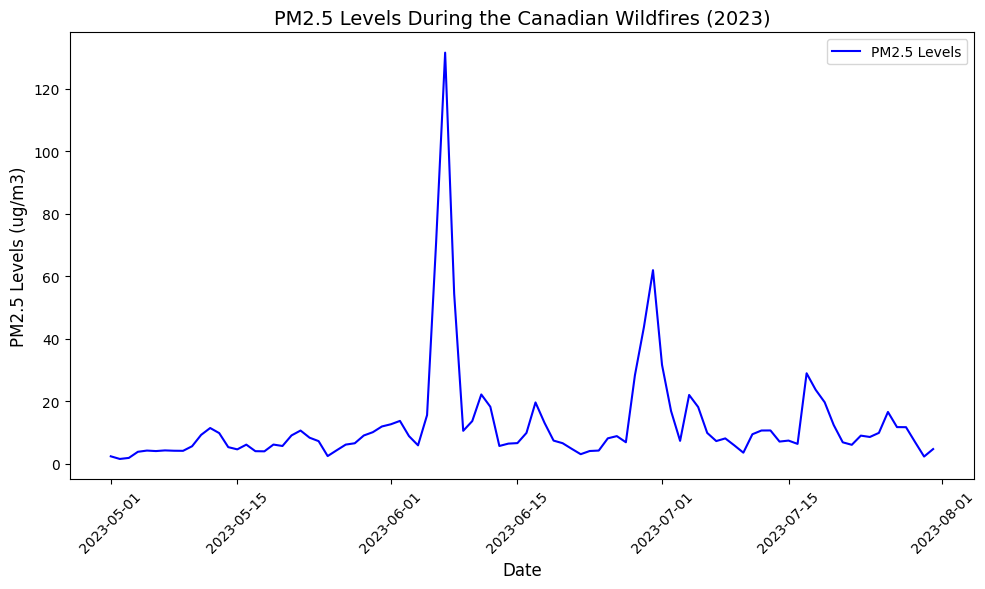

In [ ]:
#Load PM2.5 dataset
pm25data = pd.read_csv('pm2.5.csv')

# inspect dataset to understand structure
print(pm25data.head())

# check for column names and data types
print(pm25data.columns)
print(pm25data.info())

# convert date column to datetime format
pm25data['Date'] = pd.to_datetime(pm25data['Date'])

#Rename column for ease of use
pm25data=pm25data.rename(columns={'Daily Mean PM2.5 Concentration':'PM2.5 Concentration'})

#Filter PM2.5 data
pm25_filtered= pm25data[(pm25data['Date'] >= start_date) & (pm25data['Date'] <= end_date)][(pm25data['State'] == state)]

print(pm25_filtered[['Date','PM2.5 Concentration','Units','State']].head())

#Group data by dates
pm25_agg=pm25_filtered.groupby('Date').agg(
    {'PM2.5 Concentration': 'mean'}
).reset_index()

#Analyze PM2.5 Concentration Data and Graph
plt.figure(figsize=(10, 6))
plt.plot(pm25_agg['Date'], pm25_agg['PM2.5 Concentration'], label='PM2.5 Levels', color='blue')
plt.title('PM2.5 Levels During the Canadian Wildfires (2023)', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('PM2.5 Levels (ug/m3)', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.legend()
plt.show()

        Date  PM2.5 Concentration  NO2 Concentration        AQI
0 2023-05-01             2.432143             14.260  12.250000
1 2023-05-02             1.590625             24.820   8.000000
2 2023-05-03             1.916667             18.000  11.250000
3 2023-05-04             3.877419             29.075  27.444444
4 2023-05-05             4.268750             30.800  28.833333


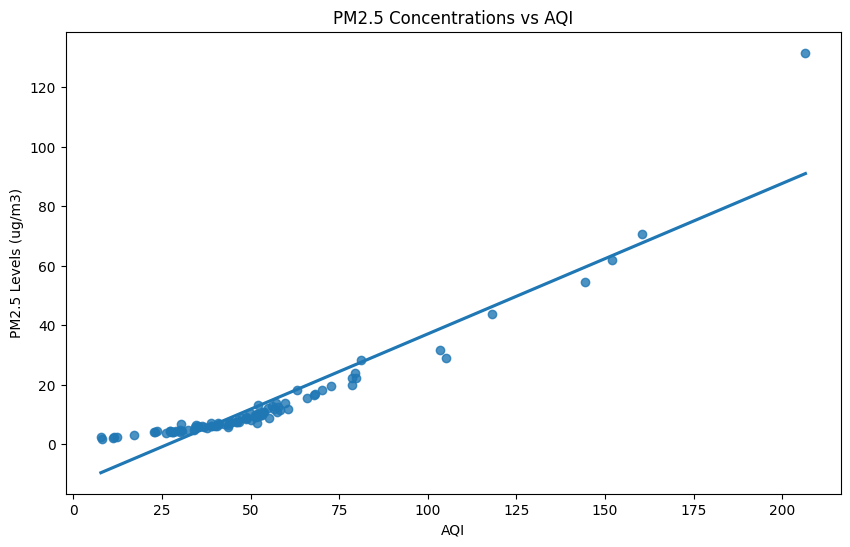

Correlation between PM2.5 levels and AQI during the wildfires: 0.94


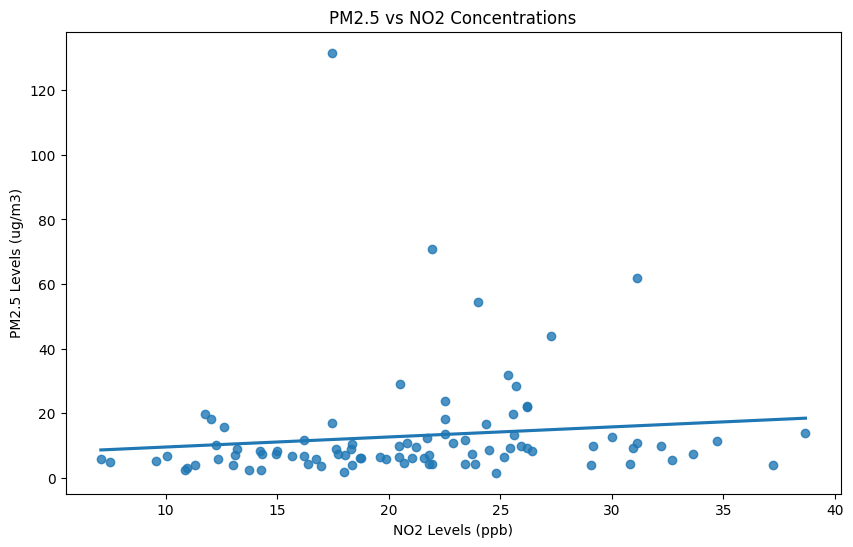

Correlation between PM2.5 levels and NO2 levels during the wildfires: 0.12


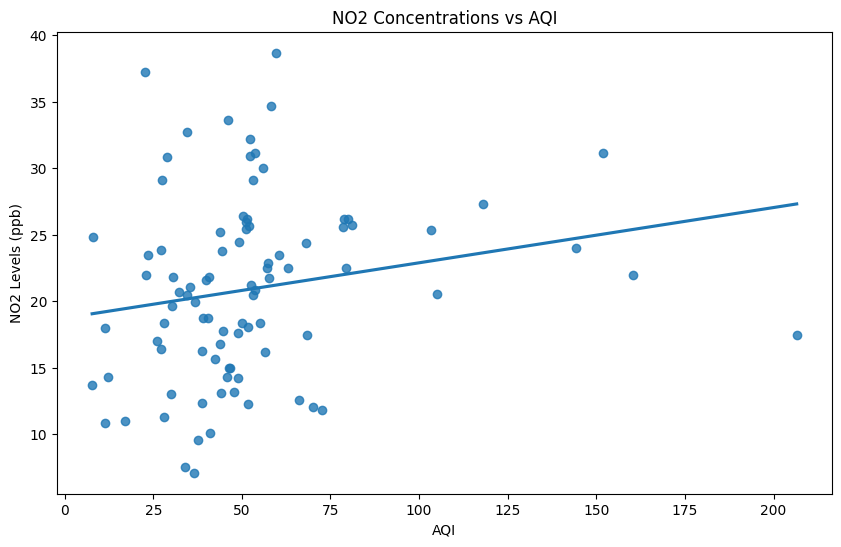

Correlation between NO2 levels and AQI during the wildfires: 0.19


In [ ]:
#join NO2 and PM2.5 charts
pm25_no2_aqi=pd.merge(pm25_agg, no2_agg, how='left', on=['Date'])
pm25_no2_aqi=pd.merge(pm25_no2_aqi, df_pm25agg, how='left', on=['Date'])
print(pm25_no2_aqi.head())

#PM2.5 vs AQI graph
plt.figure(figsize=(10, 6))
sns.regplot(pm25_no2_aqi,x='AQI', y='PM2.5 Concentration', ci=False)
plt.title('PM2.5 Concentrations vs AQI')
plt.xlabel('AQI')
plt.ylabel('PM2.5 Levels (ug/m3)')
plt.show()

#correlation between PM2.5 and AQI
corr=pm25_no2_aqi['PM2.5 Concentration'].corr(pm25_no2_aqi['AQI'])
print(f'Correlation between PM2.5 levels and AQI during the wildfires: {corr:.2f}')

#PM2.5 vs NO2
plt.figure(figsize=(10, 6))
sns.regplot(pm25_no2_aqi,x='NO2 Concentration', y='PM2.5 Concentration', ci=False)
plt.title('PM2.5 vs NO2 Concentrations')
plt.xlabel('NO2 Levels (ppb)')
plt.ylabel('PM2.5 Levels (ug/m3)')
plt.show()

#correlation between PM2.5 and NO2
corr=pm25_no2_aqi['PM2.5 Concentration'].corr(pm25_no2_aqi['NO2 Concentration'])
print(f'Correlation between PM2.5 levels and NO2 levels during the wildfires: {corr:.2f}')

#NO2 vs AQI graph
plt.figure(figsize=(10, 6))
sns.regplot(pm25_no2_aqi,x='AQI', y='NO2 Concentration', ci=False)
plt.title('NO2 Concentrations vs AQI')
plt.xlabel('AQI')
plt.ylabel('NO2 Levels (ppb)')
plt.show()

#correlation between NO2 and AQI
corr=pm25_no2_aqi['NO2 Concentration'].corr(pm25_no2_aqi['AQI'])
print(f'Correlation between NO2 levels and AQI during the wildfires: {corr:.2f}')

In [ ]:
#creating a geographical heatmap of total AQI values from May to July 2023
df = pd.read_csv('daily_aqi_by_county_2023.csv')

# Convert the date column to datetime
# reusing previous code from above cells for easy reference

df['Date'] = pd.to_datetime(df['Date'])

#creating our start, end, and state values
start_date = '2023-05-01'
end_date = '2023-07-31'
state = 'New York'

filtered_df = df[(df['State Name'] == state) &
                 (df['Date'] >= start_date) &
                 (df['Date'] <= end_date)]

# Group data by county and calculate the mean AQI
# Here we are looking at the total AQI values
county_df = filtered_df.groupby('county Name')['AQI'].mean().reset_index()

# Add a complete list of counties
# fips mapping dictionary was taken from Unicede
fips_mapping = {
    'Albany': '36001',
    'Allegany': '36003',
    'Bronx': '36005',
    'Broome': '36007',
    'Cattaraugus': '36009',
    'Cayuga': '36011',
    'Chautauqua': '36013',
    'Chemung': '36015',
    'Chenango': '36017',
    'Clinton': '36019',
    'Columbia': '36021',
    'Cortland': '36023',
    'Delaware': '36025',
    'Dutchess': '36027',
    'Erie': '36029',
    'Essex': '36031',
    'Franklin': '36033',
    'Fulton': '36035',
    'Genesee': '36037',
    'Greene': '36039',
    'Hamilton': '36041',
    'Herkimer': '36043',
    'Jefferson': '36045',
    'Kings': '36047',
    'Lewis': '36049',
    'Livingston': '36051',
    'Madison': '36053',
    'Monroe': '36055',
    'Montgomery': '36057',
    'Nassau': '36059',
    'New York': '36061',
    'Niagara': '36063',
    'Oneida': '36065',
    'Onondaga': '36067',
    'Ontario': '36069',
    'Orange': '36071',
    'Orleans': '36073',
    'Oswego': '36075',
    'Otsego': '36077',
    'Putnam': '36079',
    'Queens': '36081',
    'Rensselaer': '36083',
    'Richmond': '36085',
    'Rockland': '36087',
    'St. Lawrence': '36089',
    'Saratoga': '36091',
    'Schenectady': '36093',
    'Schoharie': '36095',
    'Schuyler': '36097',
    'Seneca': '36099',
    'Steuben': '36101',
    'Suffolk': '36103',
    'Sullivan': '36105',
    'Tioga': '36107',
    'Tompkins': '36109',
    'Ulster': '36111',
    'Warren': '36113',
    'Washington': '36115',
    'Wayne': '36117',
    'Westchester': '36119',
    'Wyoming': '36121',
    'Yates': '36123'
}

# making a DataFrame of all counties
all_counties = pd.DataFrame({'county Name': list(fips_mapping.keys())})

# merging above df with existing data to include all counties
county_df = all_counties.merge(county_df, on='county Name', how='left')

# Replacing missing county values with the mean of means values
statewide_mean_aqi = county_df['AQI'].mean()
county_df['AQI'] = county_df['AQI'].fillna(statewide_mean_aqi)

# Add FIPS codes to the DataFrame
county_df['FIPS'] = county_df['county Name'].map(fips_mapping)

# Use GeoJSON for US counties
counties_geojson = 'https://raw.githubusercontent.com/plotly/datasets/master/geojson-counties-fips.json'

# Create the choropleth map using plotly.express
fig = px.choropleth(
    county_df,
    geojson=counties_geojson,
    locations='FIPS',
    color='AQI',
    color_continuous_scale='Viridis',
    scope='usa',
    title='NY County Mean AQI (May-Jul 2023)',
    labels={'AQI': 'Mean AQI'}
)

# Update map layout to focus on New York State
fig.update_geos(fitbounds="locations", visible=False)

# Render the map
fig.show()
statewide_mean_aqi
#This is showing us that our mean of means is 50.89, with the upper bounds of our mean AQI being 65 and the lower being 40

50.890263244013994

In [ ]:
#making the same plot from Jan - April to see if there was any difference in AQI
start_date = '2023-01-01'
end_date = '2023-04-30'
state = 'New York'

filtered_df = df[(df['State Name'] == state) &
                 (df['Date'] >= start_date) &
                 (df['Date'] <= end_date)]

# Group data by county and calculate the mean AQI
# Here we are looking at the total AQI values
county_df = filtered_df.groupby('county Name')['AQI'].mean().reset_index()

# Add a complete list of counties
# fips mapping dictionary was taken from Unicede
fips_mapping = {
    'Albany': '36001',
    'Allegany': '36003',
    'Bronx': '36005',
    'Broome': '36007',
    'Cattaraugus': '36009',
    'Cayuga': '36011',
    'Chautauqua': '36013',
    'Chemung': '36015',
    'Chenango': '36017',
    'Clinton': '36019',
    'Columbia': '36021',
    'Cortland': '36023',
    'Delaware': '36025',
    'Dutchess': '36027',
    'Erie': '36029',
    'Essex': '36031',
    'Franklin': '36033',
    'Fulton': '36035',
    'Genesee': '36037',
    'Greene': '36039',
    'Hamilton': '36041',
    'Herkimer': '36043',
    'Jefferson': '36045',
    'Kings': '36047',
    'Lewis': '36049',
    'Livingston': '36051',
    'Madison': '36053',
    'Monroe': '36055',
    'Montgomery': '36057',
    'Nassau': '36059',
    'New York': '36061',
    'Niagara': '36063',
    'Oneida': '36065',
    'Onondaga': '36067',
    'Ontario': '36069',
    'Orange': '36071',
    'Orleans': '36073',
    'Oswego': '36075',
    'Otsego': '36077',
    'Putnam': '36079',
    'Queens': '36081',
    'Rensselaer': '36083',
    'Richmond': '36085',
    'Rockland': '36087',
    'St. Lawrence': '36089',
    'Saratoga': '36091',
    'Schenectady': '36093',
    'Schoharie': '36095',
    'Schuyler': '36097',
    'Seneca': '36099',
    'Steuben': '36101',
    'Suffolk': '36103',
    'Sullivan': '36105',
    'Tioga': '36107',
    'Tompkins': '36109',
    'Ulster': '36111',
    'Warren': '36113',
    'Washington': '36115',
    'Wayne': '36117',
    'Westchester': '36119',
    'Wyoming': '36121',
    'Yates': '36123'
}

# making a DataFrame of all counties

all_counties = pd.DataFrame({'county Name': list(fips_mapping.keys())})

# merging above df with existing data to include all counties

county_df = all_counties.merge(county_df, on='county Name', how='left')

# Replacing missing county values with the mean of means values
statewide_mean_aqi = county_df['AQI'].mean()
county_df['AQI'] = county_df['AQI'].fillna(statewide_mean_aqi)

# Add FIPS codes to the DataFrame
county_df['FIPS'] = county_df['county Name'].map(fips_mapping)

# Use GeoJSON for US counties
counties_geojson = 'https://raw.githubusercontent.com/plotly/datasets/master/geojson-counties-fips.json'

# Create the choropleth map using plotly.express
fig = px.choropleth(
    county_df,
    geojson=counties_geojson,
    locations='FIPS',
    color='AQI',
    color_continuous_scale='Viridis',
    scope='usa',
    title='NY County Mean AQI (Jan - April 2023)',
    labels={'AQI': 'Mean AQI'}
)

# Update map layout to focus on New York State
fig.update_geos(fitbounds="locations", visible=False)

# Render the map
fig.show()
statewide_mean_aqi
# we can see that the mean of mean AQI's is 41.42 which is about 9 lower than our previous mean of means value.
# Additionally we can see that the upper bound for our mean AQI is 50 with our lower being 35, a fairly large difference from the other(May - Jul) bounds.
# From this we can conclude that

41.42051410669987